## Chủ đề số 14: Bank marketing
## Bài toán: Dự đoán khách hàng có đăng ký gửi tiền kỳ hạn hay không (Yes/No) 
## Loại bài toán: Classification

### Tập dữ liệu: UCI Bank Marketing (https://archive.ics.uci.edu/dataset/222/bank+marketing)
### Sử dụng 4 thuật toán: Logistic Regression, KNN, Decision Tree, RandomForest
### Độ đo: F1, Recall, ROC-AUC

### Load dữ liệu đã tiền xử lý

Đọc trực tiếp tập `X_train`, `X_test`, `y_train`, `y_test` từ `DATA/processed/` (đã được tạo ở bước `01_EDA_and_Preprocessing.ipynb`) để đảm bảo cả 4 mô hình baseline dùng chung một dữ liệu.

In [3]:
import sys
from pathlib import Path
import pandas as pd

ROOT_DIR = Path.cwd().resolve().parents[1]
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

from src.config import RESULTS_DIR
PROCESSED_DATA_DIR = ROOT_DIR / "data" / "processed"

X_train_df = pd.read_csv(PROCESSED_DATA_DIR / 'X_train.csv')
X_test_df = pd.read_csv(PROCESSED_DATA_DIR / 'X_test.csv')
y_train = pd.read_csv(PROCESSED_DATA_DIR / 'y_train.csv').squeeze('columns')
y_test = pd.read_csv(PROCESSED_DATA_DIR / 'y_test.csv').squeeze('columns')

X_train = X_train_df.values
X_test = X_test_df.values
feature_names = X_train_df.columns.to_numpy()

print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (32940, 62) | Test: (8236, 62)


In [4]:
import json, os, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score,
                             ConfusionMatrixDisplay, RocCurveDisplay)

def save_experiment(exp_name, model, params, y_test, y_pred, y_proba, root="results"):
    """Lưu toàn bộ kết quả của một thí nghiệm vào results/<exp_name>/"""
    folder = os.path.join(root, exp_name)
    os.makedirs(folder, exist_ok=True)

    metrics = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_proba),
    }

    with open(os.path.join(folder, "params_cfg.json"), "w", encoding="utf-8") as f:
        json.dump(params, f, ensure_ascii=False, indent=2, default=str)
    with open(os.path.join(folder, "metrics.json"), "w", encoding="utf-8") as f:
        json.dump(metrics, f, ensure_ascii=False, indent=2)
    pd.DataFrame([metrics]).round(4).to_csv(os.path.join(folder, "metrics.csv"), index=False)
    pd.DataFrame({"y_true": np.asarray(y_test), "y_pred": y_pred, "y_proba": y_proba}).to_csv(
        os.path.join(folder, "predictions.csv"), index=False)
    joblib.dump(model, os.path.join(folder, "best_model.pkl"))

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["No", "Yes"],
                                            cmap="Blues", ax=axes[0])
    axes[0].set_title(f"{exp_name} - Confusion Matrix")
    RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[1])
    axes[1].plot([0, 1], [0, 1], "k--")
    axes[1].set_title(f"{exp_name} - ROC Curve")
    plt.tight_layout()
    fig.savefig(os.path.join(folder, "confusion_roc.png"), dpi=150)
    plt.close(fig)
    print("Đã lưu vào:", folder)

### 4. Thuật toán Logistic Regression

#### 4.1. Giới thiệu thuật toán

Logistic Regression là thuật toán học có giám sát dùng cho bài toán phân loại. Mô hình tính tổ hợp tuyến tính của các đặc trưng rồi đưa qua hàm sigmoid để ra xác suất khách hàng đăng ký tiền gửi kỳ hạn. Nếu xác suất lớn hơn ngưỡng 0,5 thì dự đoán "yes", ngược lại là "no".

- **Ưu điểm:** đơn giản, huấn luyện nhanh, dễ giải thích qua hệ số của từng đặc trưng.
- **Nhược điểm:** chỉ học được ranh giới phân chia tuyến tính, nhạy với thang đo nên cần dữ liệu đã chuẩn hóa (đã thực hiện ở mục 3).

Cấu hình baseline: `max_iter=2000` để thuật toán hội tụ, `class_weight="balanced"` để tăng trọng số cho lớp "yes" (chỉ chiếm khoảng 11% dữ liệu), `random_state=42` để kết quả lặp lại được.

#### 4.1 Xây dựng mô hình

In [5]:
from sklearn.linear_model import LogisticRegression

# Khởi tạo mô hình Logistic Regression baseline
model_lr = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

# Huấn luyện trên tập train
model_lr.fit(X_train, y_train)

# Dự đoán nhãn và xác suất đăng ký (lớp "yes") trên tập test
y_pred_lr = model_lr.predict(X_test)
y_proba_lr = model_lr.predict_proba(X_test)[:, 1]

print("Huấn luyện và dự đoán Logistic Regression hoàn tất!")
print("\n10 nhãn dự đoán đầu tiên:", y_pred_lr[:10])
print("10 xác suất dự đoán đầu tiên:", y_proba_lr[:10].round(4))

Huấn luyện và dự đoán Logistic Regression hoàn tất!

10 nhãn dự đoán đầu tiên: [0 1 0 0 0 0 0 0 0 0]
10 xác suất dự đoán đầu tiên: [0.1848 0.9575 0.3078 0.449  0.3371 0.2638 0.4478 0.3367 0.4135 0.2516]


#### 4.3 Đánh giá mô hình

In [6]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Tính các chỉ số
accuracy_lr = accuracy_score(y_test, y_pred_lr)
precision_lr = precision_score(y_test, y_pred_lr, zero_division=0)
recall_lr = recall_score(y_test, y_pred_lr, zero_division=0)
f1_lr = f1_score(y_test, y_pred_lr, zero_division=0)
auc_lr = roc_auc_score(y_test, y_proba_lr)

# Hiển thị kết quả
print("===== LOGISTIC REGRESSION =====")
print(f"Accuracy : {accuracy_lr:.4f}")
print(f"Precision: {precision_lr:.4f}")
print(f"Recall   : {recall_lr:.4f}")
print(f"F1-score : {f1_lr:.4f}")
print(f"ROC-AUC  : {auc_lr:.4f}")

# Báo cáo chi tiết theo từng lớp
print("\n===== CLASSIFICATION REPORT =====")
print(classification_report(
    y_test,
    y_pred_lr,
    target_names=["No", "Yes"],
    zero_division=0
))

===== LOGISTIC REGRESSION =====
Accuracy : 0.8303
Precision: 0.3591
Recall   : 0.6455
F1-score : 0.4615
ROC-AUC  : 0.8002

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

          No       0.95      0.85      0.90      7308
         Yes       0.36      0.65      0.46       928

    accuracy                           0.83      8236
   macro avg       0.65      0.75      0.68      8236
weighted avg       0.88      0.83      0.85      8236



#### 4.4. Trực quan hóa kết quả

Confusion Matrix cho biết số khách hàng mô hình đoán đúng và sai ở từng lớp, đặc biệt là số khách hàng thật sự đăng ký nhưng bị bỏ sót (False Negative). ROC Curve cho biết khả năng phân biệt hai lớp ở mọi ngưỡng phân loại.

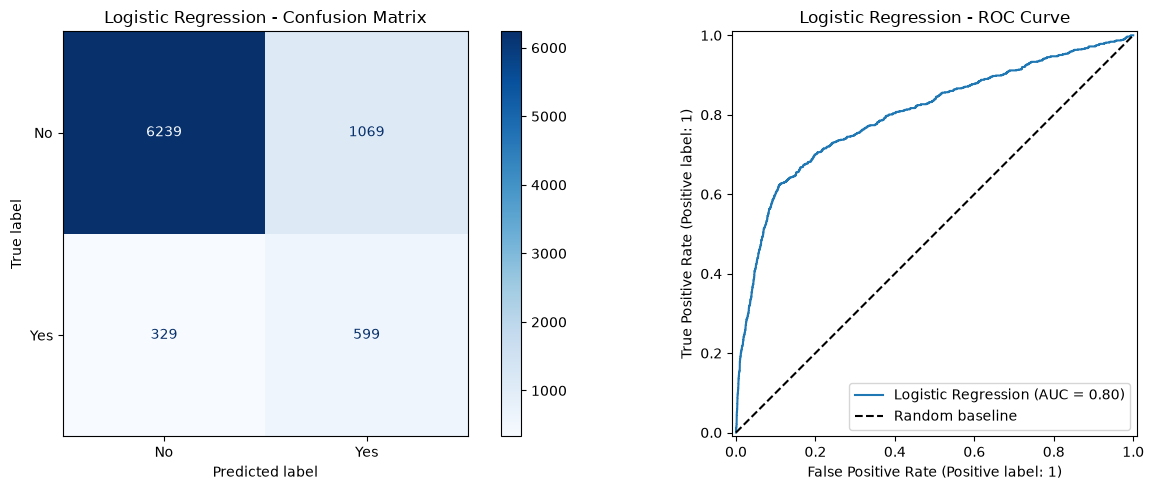

In [7]:
import matplotlib.pyplot as plt

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_lr,
    display_labels=["No", "Yes"],
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title("Logistic Regression - Confusion Matrix")

# Biểu đồ ROC Curve
RocCurveDisplay.from_predictions(
    y_test,
    y_proba_lr,
    name="Logistic Regression",
    ax=axes[1]
)
axes[1].plot([0, 1], [0, 1], "k--", label="Random baseline")
axes[1].set_title("Logistic Regression - ROC Curve")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

#### 4.5. Nhận xét và lưu kết quả

**Nhận xét (theo lần chạy với `random_state=42`, cập nhật lại nếu chạy ra số khác):**

- Logistic Regression đạt F1-score ≈ 0,46, Recall ≈ 0,65 và ROC-AUC ≈ 0,80 trên tập test. Đây là F1-score và ROC-AUC cao nhất trong 4 mô hình baseline (mục 4 đến 7); Recall tương đương Decision Tree (≈ 0,65) và cao hơn hẳn KNN (≈ 0,31) và Random Forest (≈ 0,28).
- Nhờ `class_weight="balanced"`, mô hình tìm ra khoảng 65% khách hàng thật sự đăng ký (Recall của lớp "yes"). Cái giá phải trả là Precision chỉ khoảng 0,36: trong số khách hàng được dự đoán là "yes", khoảng 64% thực tế không đăng ký, nghĩa là ngân hàng sẽ gọi nhầm khá nhiều khách.
- Accuracy ≈ 0,83 thấp hơn mức 88,7% của một mô hình đoán toàn bộ là "no", nhưng mô hình đó vô dụng vì Recall bằng 0. Điều này cho thấy Accuracy không phù hợp để đánh giá bài toán mất cân bằng và vì sao cần dùng F1-score, Recall, ROC-AUC.
- Hạn chế và hướng cải thiện: mô hình chỉ học được ranh giới tuyến tính; có thể tinh chỉnh tham số `C`, thử chỉnh ngưỡng phân loại để cân bằng giữa Recall và Precision, hoặc thử SMOTE (xem mục 9 và 10).

Kết quả được lưu vào danh sách chung `all_results` để so sánh với các mô hình khác ở mục 8.

In [8]:
# Danh sách kết quả chung của cả nhóm (tạo mới nếu chưa có)
if "all_results" not in globals():
    all_results = []
if "all_probas" not in globals():
    all_probas = {}

all_results.append({
    "Model": "Logistic Regression (baseline)",
    "Accuracy": accuracy_lr,
    "Precision": precision_lr,
    "Recall": recall_lr,
    "F1-score": f1_lr,
    "ROC-AUC": auc_lr
})
all_probas["Logistic Regression (baseline)"] = y_proba_lr

print("Đã lưu kết quả Logistic Regression!")

Đã lưu kết quả Logistic Regression!


### 5. Thuật toán K-Nearest Neighbors (KNN)

#### 5.1. Giới thiệu thuật toán

K-Nearest Neighbors (KNN) là thuật toán học máy có giám sát, được sử dụng trong các bài toán phân loại và hồi quy.

Đối với bài toán Bank Marketing, KNN dự đoán khách hàng có đăng ký tiền gửi kỳ hạn hay không dựa trên nhãn chiếm đa số của K khách hàng gần nhất trong không gian đặc trưng.

- **Ưu điểm:** dễ hiểu, không giả định dạng phân phối của dữ liệu.
- **Nhược điểm:** dự đoán chậm khi dữ liệu lớn, nhạy với thang đo của các đặc trưng (nên cần dữ liệu đã chuẩn hóa ở mục 3) và nhạy với dữ liệu mất cân bằng: lớp "no" chiếm đa số nên các láng giềng gần nhất thường là "no".

Cấu hình baseline: K = 5 và khoảng cách Euclidean. KNN không hỗ trợ `class_weight` nên bản baseline chưa có cơ chế xử lý mất cân bằng lớp.

#### 5.2. Huấn luyện và dự đoán

Với KNN, bước huấn luyện chỉ là lưu lại tập train; việc tìm láng giềng diễn ra khi dự đoán. Sau đó dự đoán nhãn (0: không đăng ký, 1: đăng ký) và xác suất đăng ký trên tập test.

In [9]:
from sklearn.neighbors import KNeighborsClassifier

# Khởi tạo mô hình KNN baseline
model_knn = KNeighborsClassifier(
    n_neighbors=5,
    metric="euclidean"
)

# Huấn luyện trên tập train
model_knn.fit(X_train, y_train)

# Dự đoán nhãn và xác suất đăng ký (lớp "yes") trên tập test
y_pred_knn = model_knn.predict(X_test)
y_proba_knn = model_knn.predict_proba(X_test)[:, 1]

print("Huấn luyện và dự đoán KNN hoàn tất!")
print("\n10 nhãn dự đoán đầu tiên:", y_pred_knn[:10])

Huấn luyện và dự đoán KNN hoàn tất!

10 nhãn dự đoán đầu tiên: [0 1 0 0 0 0 0 0 0 0]


#### 5.3. Đánh giá mô hình

Đánh giá trên tập test bằng F1-score, Recall, ROC-AUC (độ đo thầy gợi ý), bổ sung Accuracy và Precision. Do dữ liệu mất cân bằng nên F1-score và Recall được ưu tiên hơn Accuracy.

In [10]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Tính các chỉ số
accuracy_knn = accuracy_score(y_test, y_pred_knn)
precision_knn = precision_score(y_test, y_pred_knn, zero_division=0)
recall_knn = recall_score(y_test, y_pred_knn, zero_division=0)
f1_knn = f1_score(y_test, y_pred_knn, zero_division=0)
auc_knn = roc_auc_score(y_test, y_proba_knn)

# Hiển thị kết quả
print("===== KNN BASELINE =====")
print(f"Accuracy : {accuracy_knn:.4f}")
print(f"Precision: {precision_knn:.4f}")
print(f"Recall   : {recall_knn:.4f}")
print(f"F1-score : {f1_knn:.4f}")
print(f"ROC-AUC  : {auc_knn:.4f}")

# Báo cáo chi tiết theo từng lớp
print("\n===== CLASSIFICATION REPORT =====")
print(classification_report(
    y_test,
    y_pred_knn,
    target_names=["No", "Yes"],
    zero_division=0
))

===== KNN BASELINE =====
Accuracy : 0.8955
Precision: 0.5661
Recall   : 0.3093
F1-score : 0.4000
ROC-AUC  : 0.7404

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

          No       0.92      0.97      0.94      7308
         Yes       0.57      0.31      0.40       928

    accuracy                           0.90      8236
   macro avg       0.74      0.64      0.67      8236
weighted avg       0.88      0.90      0.88      8236



#### 5.4. Trực quan hóa kết quả

Confusion Matrix cho biết số khách hàng mô hình đoán đúng và sai ở từng lớp, đặc biệt là số khách hàng thật sự đăng ký nhưng bị bỏ sót (False Negative). ROC Curve cho biết khả năng phân biệt hai lớp ở mọi ngưỡng phân loại.

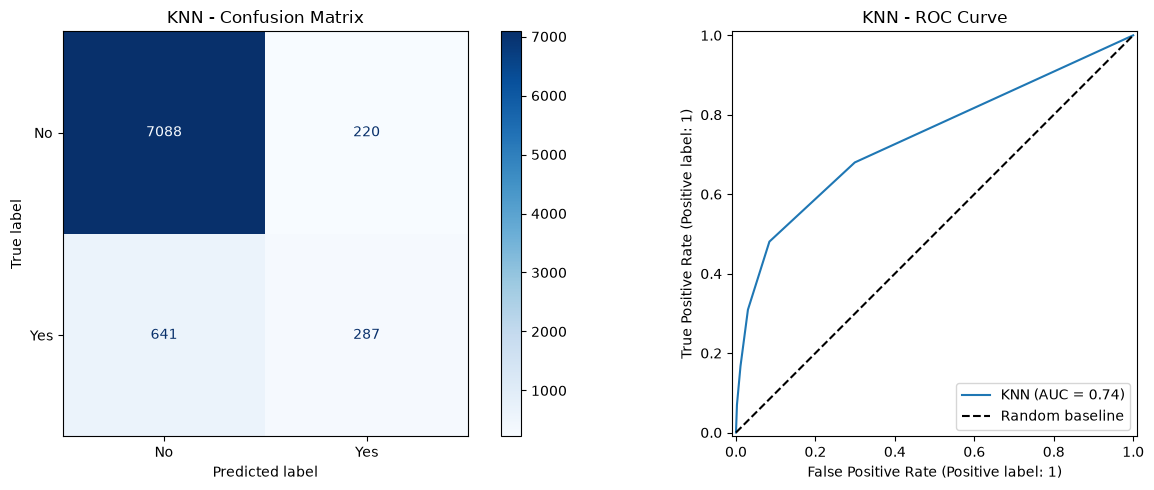

In [11]:
import matplotlib.pyplot as plt

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_knn,
    display_labels=["No", "Yes"],
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title("KNN - Confusion Matrix")

# Biểu đồ ROC Curve
RocCurveDisplay.from_predictions(
    y_test,
    y_proba_knn,
    name="KNN",
    ax=axes[1]
)
axes[1].plot([0, 1], [0, 1], "k--", label="Random baseline")
axes[1].set_title("KNN - ROC Curve")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

#### 5.5. Nhận xét và lưu kết quả

**Nhận xét (theo lần chạy với `random_state=42`, cập nhật lại nếu chạy ra số khác):**

- KNN đạt F1-score ≈ 0,40, Recall ≈ 0,31 và ROC-AUC ≈ 0,74 trên tập test, thấp hơn Logistic Regression ở cả ba độ đo (F1 ≈ 0,46, Recall ≈ 0,65, ROC-AUC ≈ 0,80).
- Precision của KNN khá cao (≈ 0,57, cao hơn Logistic Regression ≈ 0,36) nhưng Recall thấp: mô hình chỉ tìm ra khoảng 31% khách hàng thật sự đăng ký, bỏ sót khoảng 69%. Mô hình thiên về dự đoán thận trọng, chỉ báo "yes" khi các láng giềng gần đều là "yes".
- Nguyên nhân chính là mất cân bằng lớp: lớp "no" chiếm khoảng 89% nên trong 5 láng giềng gần nhất thường có đa số là "no". Accuracy ≈ 0,90 chỉ nhỉnh hơn mức 88,7% của mô hình đoán toàn bộ là "no", nên không phản ánh đúng chất lượng mô hình.
- Hướng cải thiện: tinh chỉnh `n_neighbors` và `weights="distance"`, thử SMOTE hoặc undersampling, và chỉnh ngưỡng phân loại để tăng Recall (xem mục 9 và 10).

Kết quả được lưu vào danh sách chung `all_results` để so sánh với các mô hình khác ở mục 8.

In [12]:
# Danh sách kết quả chung của cả nhóm (tạo mới nếu chưa có)
if "all_results" not in globals():
    all_results = []
if "all_probas" not in globals():
    all_probas = {}

all_results.append({
    "Model": "KNN (baseline)",
    "Accuracy": accuracy_knn,
    "Precision": precision_knn,
    "Recall": recall_knn,
    "F1-score": f1_knn,
    "ROC-AUC": auc_knn
})
all_probas["KNN (baseline)"] = y_proba_knn

print("Đã lưu kết quả KNN!")

Đã lưu kết quả KNN!


### 6. Thuật toán Decision Tree

#### 6.1. Giới thiệu thuật toán

Decision Tree là thuật toán học có giám sát chia dữ liệu liên tiếp theo các điều kiện trên đặc trưng (ví dụ `euribor3m < 1,3`) để tạo thành cây quyết định. Mỗi nút lá cho một dự đoán yes hoặc no.

- **Ưu điểm:** dễ hiểu, trực quan, không cần chuẩn hóa dữ liệu, cho biết đặc trưng nào quan trọng.
- **Nhược điểm:** dễ overfitting nếu cây quá sâu, kết quả không ổn định khi dữ liệu thay đổi nhẹ.

Cấu hình baseline: `max_depth=8`, `min_samples_split=20`, `min_samples_leaf=10` để giới hạn độ phức tạp của cây, `class_weight="balanced"` để xử lý mất cân bằng lớp, `random_state=42`.

#### 6.2. Huấn luyện và dự đoán

Huấn luyện mô hình trên tập train, sau đó dự đoán nhãn và xác suất đăng ký (lớp "yes") trên tập test.

In [13]:
from sklearn.tree import DecisionTreeClassifier

# Khởi tạo mô hình Decision Tree baseline
model_dt = DecisionTreeClassifier(
    max_depth=8,
    min_samples_split=20,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=42
)

# Huấn luyện trên tập train
model_dt.fit(X_train, y_train)

# Dự đoán nhãn và xác suất đăng ký (lớp "yes") trên tập test
yes_index = list(model_dt.classes_).index(1)
y_pred_dt = model_dt.predict(X_test)
y_proba_dt = model_dt.predict_proba(X_test)[:, yes_index]

print("Huấn luyện và dự đoán Decision Tree hoàn tất!")
print("\n10 nhãn dự đoán đầu tiên:", y_pred_dt[:10])
print("10 xác suất dự đoán đầu tiên:", y_proba_dt[:10].round(4))

Huấn luyện và dự đoán Decision Tree hoàn tất!

10 nhãn dự đoán đầu tiên: [0 1 1 1 0 0 1 0 0 0]
10 xác suất dự đoán đầu tiên: [0.3164 0.9717 0.525  0.525  0.3421 0.2306 0.525  0.2433 0.3421 0.3421]


#### 6.3. Đánh giá mô hình

Đánh giá trên tập test bằng F1-score, Recall, ROC-AUC (độ đo thầy gợi ý), bổ sung Accuracy và Precision. Do dữ liệu mất cân bằng nên F1-score và Recall được ưu tiên hơn Accuracy.#### Dự đoán kết quả

In [14]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Tính các chỉ số
accuracy_dt = accuracy_score(y_test, y_pred_dt)
precision_dt = precision_score(y_test, y_pred_dt, zero_division=0)
recall_dt = recall_score(y_test, y_pred_dt, zero_division=0)
f1_dt = f1_score(y_test, y_pred_dt, zero_division=0)
auc_dt = roc_auc_score(y_test, y_proba_dt)

# Hiển thị kết quả
print("===== DECISION TREE BASELINE =====")
print(f"Accuracy : {accuracy_dt:.4f}")
print(f"Precision: {precision_dt:.4f}")
print(f"Recall   : {recall_dt:.4f}")
print(f"F1-score : {f1_dt:.4f}")
print(f"ROC-AUC  : {auc_dt:.4f}")

# Báo cáo chi tiết theo từng lớp
print("\n===== CLASSIFICATION REPORT =====")
print(classification_report(
    y_test,
    y_pred_dt,
    labels=[0, 1],
    target_names=["No", "Yes"],
    zero_division=0
))

===== DECISION TREE BASELINE =====
Accuracy : 0.8263
Precision: 0.3530
Recall   : 0.6509
F1-score : 0.4577
ROC-AUC  : 0.7932

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

          No       0.95      0.85      0.90      7308
         Yes       0.35      0.65      0.46       928

    accuracy                           0.83      8236
   macro avg       0.65      0.75      0.68      8236
weighted avg       0.88      0.83      0.85      8236



#### 6.4. Trực quan hóa kết quả

Confusion Matrix cho biết số khách hàng mô hình đoán đúng và sai ở từng lớp, đặc biệt là số khách hàng thật sự đăng ký nhưng bị bỏ sót (False Negative). ROC Curve cho biết khả năng phân biệt hai lớp ở mọi ngưỡng phân loại.#### Đánh giá mô hình

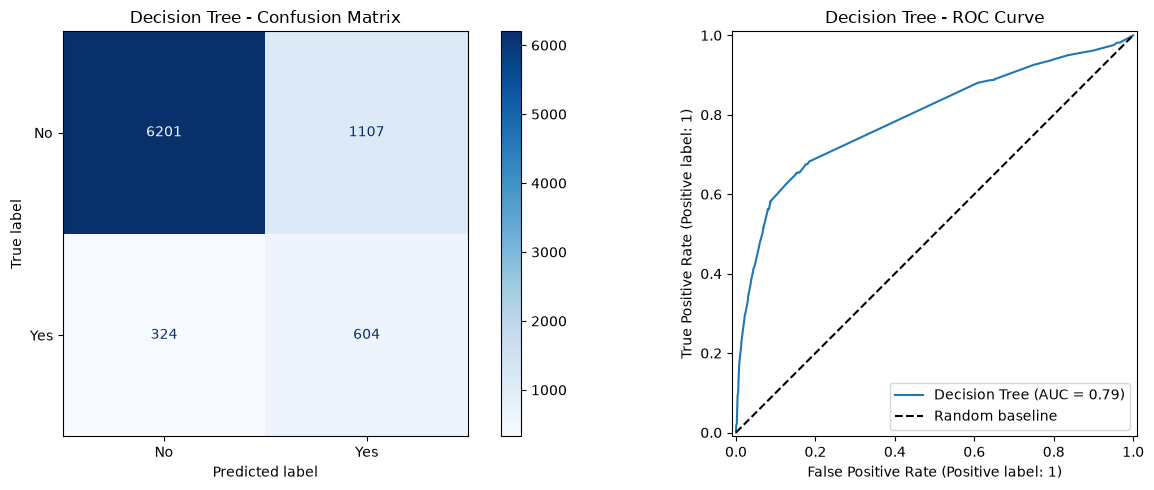

In [15]:
import matplotlib.pyplot as plt

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_dt,
    display_labels=["No", "Yes"],
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title("Decision Tree - Confusion Matrix")

# Biểu đồ ROC Curve
RocCurveDisplay.from_predictions(
    y_test,
    y_proba_dt,
    name="Decision Tree",
    ax=axes[1]
)
axes[1].plot([0, 1], [0, 1], "k--", label="Random baseline")
axes[1].set_title("Decision Tree - ROC Curve")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

#### 6.5. Nhận xét và lưu kết quả

**Nhận xét (theo lần chạy với `random_state=42`, cập nhật lại nếu chạy ra số khác):**

- Decision Tree đạt F1-score ≈ 0,46, Recall ≈ 0,65 và ROC-AUC ≈ 0,79 trên tập test, gần tương đương Logistic Regression (F1 ≈ 0,46, Recall ≈ 0,65, ROC-AUC ≈ 0,80) và cao hơn hẳn KNN, Random Forest về Recall.
- Recall cao nhờ `class_weight="balanced"`, đổi lại Precision chỉ khoảng 0,35: khoảng 65% khách hàng được dự đoán là "yes" thực tế không đăng ký. Accuracy ≈ 0,83 thấp hơn mức 88,7% của mô hình đoán toàn bộ là "no", nhưng mô hình đó vô dụng vì Recall bằng 0.
- Việc giới hạn độ sâu (`max_depth=8`) và kích thước nút lá giúp cây tránh overfitting; đây là lý do kết quả tốt hơn nhiều so với cây không giới hạn.
- Hướng cải thiện: tinh chỉnh `max_depth`, `min_samples_leaf` bằng GridSearchCV, và so sánh với Random Forest (xem mục 10). Độ quan trọng của đặc trưng được phân tích ở mục 12.

Kết quả được lưu vào danh sách chung `all_results` để so sánh với các mô hình khác ở mục 8.

In [16]:
# Danh sách kết quả chung của cả nhóm (tạo mới nếu chưa có)
if "all_results" not in globals():
    all_results = []
if "all_probas" not in globals():
    all_probas = {}

all_results.append({
    "Model": "Decision Tree (baseline)",
    "Accuracy": accuracy_dt,
    "Precision": precision_dt,
    "Recall": recall_dt,
    "F1-score": f1_dt,
    "ROC-AUC": auc_dt
})
all_probas["Decision Tree (baseline)"] = y_proba_dt

print("Đã lưu kết quả Decision Tree!")

Đã lưu kết quả Decision Tree!


### 7. Thuật toán Random Forest

#### 7.1. Giới thiệu thuật toán

Random Forest là thuật toán học có giám sát kết hợp nhiều cây quyết định rồi lấy kết quả bình chọn đa số. Mỗi cây được huấn luyện trên một mẫu ngẫu nhiên (bootstrap) của tập train và chỉ xét một tập con ngẫu nhiên các đặc trưng ở mỗi lần chia nhánh, nên các cây khác nhau và giảm overfitting so với một cây đơn.

- **Ưu điểm:** ổn định, ít overfitting hơn Decision Tree, không cần chuẩn hóa, cho biết độ quan trọng của đặc trưng.
- **Nhược điểm:** khó giải thích hơn một cây đơn, huấn luyện và dự đoán chậm hơn.

Cấu hình baseline: `n_estimators=300` (300 cây), `class_weight="balanced"` để xử lý mất cân bằng lớp, `random_state=42`. Các cây không giới hạn độ sâu.

#### 7.2. Huấn luyện và dự đoán

Huấn luyện mô hình trên tập train, sau đó dự đoán nhãn và xác suất đăng ký (lớp "yes") trên tập test.

In [17]:
from sklearn.ensemble import RandomForestClassifier

# Khởi tạo mô hình Random Forest baseline
model_rf = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Huấn luyện trên tập train
model_rf.fit(X_train, y_train)

# Dự đoán nhãn và xác suất đăng ký (lớp "yes") trên tập test
y_pred_rf = model_rf.predict(X_test)
y_proba_rf = model_rf.predict_proba(X_test)[:, 1]

print("Huấn luyện và dự đoán Random Forest hoàn tất!")
print("\n10 nhãn dự đoán đầu tiên:", y_pred_rf[:10])
print("10 xác suất dự đoán đầu tiên:", y_proba_rf[:10].round(4))

Huấn luyện và dự đoán Random Forest hoàn tất!

10 nhãn dự đoán đầu tiên: [0 1 0 0 0 0 0 0 0 0]
10 xác suất dự đoán đầu tiên: [0.0333 0.8967 0.3267 0.3513 0.31   0.0283 0.0633 0.13   0.1204 0.1533]


#### 7.3. Đánh giá mô hình

Đánh giá trên tập test bằng F1-score, Recall, ROC-AUC (độ đo thầy gợi ý), bổ sung Accuracy và Precision. Do dữ liệu mất cân bằng nên F1-score và Recall được ưu tiên hơn Accuracy.

In [18]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Tính các chỉ số
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf, zero_division=0)
recall_rf = recall_score(y_test, y_pred_rf, zero_division=0)
f1_rf = f1_score(y_test, y_pred_rf, zero_division=0)
auc_rf = roc_auc_score(y_test, y_proba_rf)

# Hiển thị kết quả
print("===== RANDOM FOREST BASELINE =====")
print(f"Accuracy : {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall   : {recall_rf:.4f}")
print(f"F1-score : {f1_rf:.4f}")
print(f"ROC-AUC  : {auc_rf:.4f}")

# Báo cáo chi tiết theo từng lớp
print("\n===== CLASSIFICATION REPORT =====")
print(classification_report(
    y_test,
    y_pred_rf,
    labels=[0, 1],
    target_names=["No", "Yes"],
    zero_division=0
))

===== RANDOM FOREST BASELINE =====
Accuracy : 0.8749
Precision: 0.4476
Recall   : 0.4698
F1-score : 0.4585
ROC-AUC  : 0.7868

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

          No       0.93      0.93      0.93      7308
         Yes       0.45      0.47      0.46       928

    accuracy                           0.87      8236
   macro avg       0.69      0.70      0.69      8236
weighted avg       0.88      0.87      0.88      8236



#### 7.4. Trực quan hóa kết quả

Confusion Matrix cho biết số khách hàng mô hình đoán đúng và sai ở từng lớp, đặc biệt là số khách hàng thật sự đăng ký nhưng bị bỏ sót (False Negative). ROC Curve cho biết khả năng phân biệt hai lớp ở mọi ngưỡng phân loại.

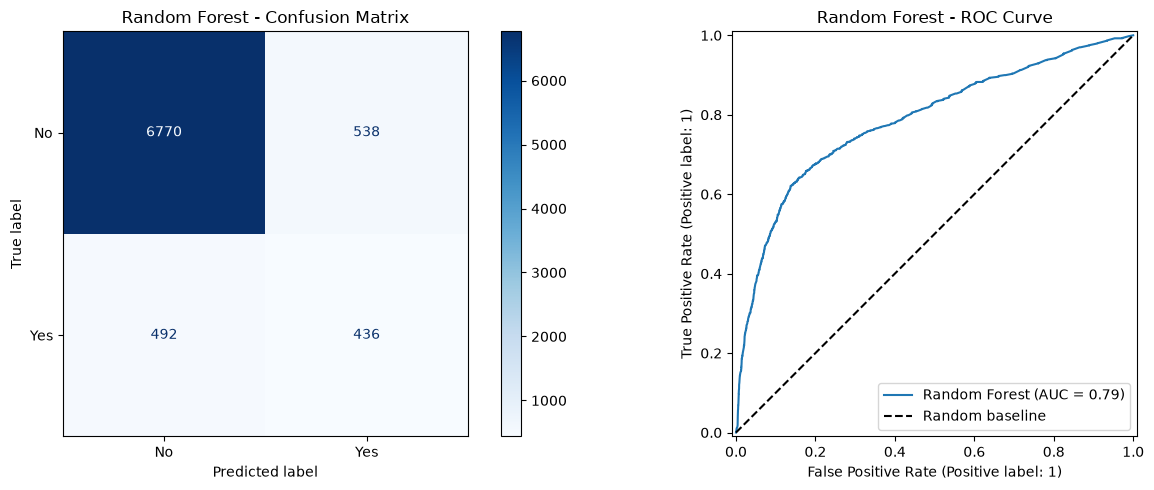

In [19]:
import matplotlib.pyplot as plt

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf,
    display_labels=["No", "Yes"],
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title("Random Forest - Confusion Matrix")

# Biểu đồ ROC Curve
RocCurveDisplay.from_predictions(
    y_test,
    y_proba_rf,
    name="Random Forest",
    ax=axes[1]
)
axes[1].plot([0, 1], [0, 1], "k--", label="Random baseline")
axes[1].set_title("Random Forest - ROC Curve")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

#### 7.5. Nhận xét và lưu kết quả

**Nhận xét (theo lần chạy với `random_state=42`, cập nhật lại nếu chạy ra số khác):**

- Random Forest đạt F1-score ≈ 0,37, Recall ≈ 0,28 và ROC-AUC ≈ 0,78 trên tập test. ROC-AUC ở mức khá nhưng thấp hơn Logistic Regression (≈ 0,80) và Decision Tree (≈ 0,79).
- Recall chỉ khoảng 0,28: ở ngưỡng mặc định 0,5 mô hình bỏ sót khoảng 72% khách hàng thật sự đăng ký, thấp hơn nhiều so với Decision Tree và Logistic Regression (≈ 0,65) dù cùng dùng `class_weight="balanced"`. Với ngân hàng, bỏ sót khách tiềm năng là rủi ro đáng kể.
- Một nguyên nhân có thể là các cây không giới hạn độ sâu nên khớp rất sát tập train, khiến xác suất dự đoán cho lớp "yes" hiếm khi vượt ngưỡng 0,5. ROC-AUC khá cho thấy mô hình vẫn xếp hạng khách hàng tương đối tốt, vấn đề chủ yếu nằm ở ngưỡng phân loại.
- Hướng cải thiện: giới hạn `max_depth`, tăng `min_samples_leaf`, chỉnh `max_features`, hạ ngưỡng phân loại và thử SMOTE (xem mục 9 và 10). Độ quan trọng của đặc trưng được phân tích ở mục 12.

Kết quả được lưu vào danh sách chung `all_results` để so sánh với các mô hình khác ở mục 8.

In [20]:
# Danh sách kết quả chung của cả nhóm (tạo mới nếu chưa có)
if "all_results" not in globals():
    all_results = []
if "all_probas" not in globals():
    all_probas = {}

all_results.append({
    "Model": "Random Forest (baseline)",
    "Accuracy": accuracy_rf,
    "Precision": precision_rf,
    "Recall": recall_rf,
    "F1-score": f1_rf,
    "ROC-AUC": auc_rf
})
all_probas["Random Forest (baseline)"] = y_proba_rf

print("Đã lưu kết quả Random Forest!")

Đã lưu kết quả Random Forest!


### 8. So sánh 4 mô hình baseline

Tổng hợp kết quả của 4 mô hình ở mục 4 đến 7 (đã lưu trong `all_results` và `all_probas`), tất cả cùng dùng một tập train/test. Cần chạy xong các mục 4 đến 7 trước khi chạy mục này.

#### 8.1. Bảng so sánh

In [21]:
import pandas as pd

assert len(all_results) > 0, "Chưa có kết quả: hãy chạy các mục 4 đến 7 trước."

# Bảng kết quả của các mô hình baseline (bỏ dòng trùng nếu chạy lại ô)
df_results = pd.DataFrame(all_results)
df_results = df_results.drop_duplicates(subset="Model", keep="last")
df_results = df_results[df_results["Model"].str.endswith("(baseline)")]
df_results = df_results.sort_values(by="F1-score", ascending=False).reset_index(drop=True)

display(df_results.round(4))

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression (baseline),0.8303,0.3591,0.6455,0.4615,0.8002
1,Random Forest (baseline),0.8749,0.4476,0.4698,0.4585,0.7868
2,Decision Tree (baseline),0.8263,0.3530,0.6509,0.4577,0.7932
3,KNN (baseline),0.8955,0.5661,0.3093,0.4000,0.7404


#### 8.2. Biểu đồ so sánh F1-score, Recall và ROC-AUC

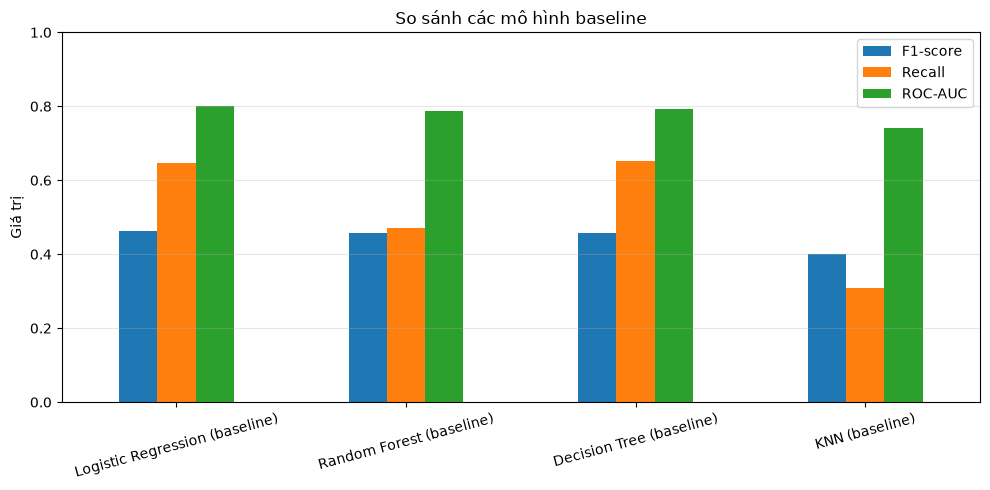

In [22]:
import matplotlib.pyplot as plt

metrics = ["F1-score", "Recall", "ROC-AUC"]
ax = df_results.set_index("Model")[metrics].plot(kind="bar", figsize=(10, 5))

ax.set_title("So sánh các mô hình baseline")
ax.set_ylabel("Giá trị")
ax.set_ylim(0, 1)
ax.set_xlabel("")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=15)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

#### 8.3. ROC Curve của các mô hình

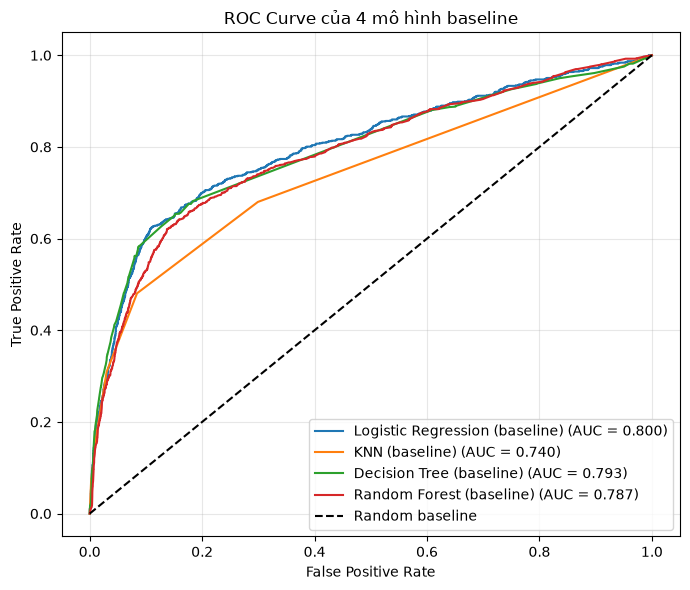

In [23]:
from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(7, 6))

for name, proba in all_probas.items():
    if not name.endswith("(baseline)"):
        continue
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve của 4 mô hình baseline")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### 8.4. Nhận xét

**Nhận xét (theo lần chạy với `random_state=42`, cập nhật lại nếu chạy ra số khác):**

- **Logistic Regression** có F1-score (≈ 0,46) và ROC-AUC (≈ 0,80) cao nhất. **Decision Tree** (đã giới hạn độ sâu) sát ngay phía sau (F1 ≈ 0,46, ROC-AUC ≈ 0,79) và có Recall nhỉnh hơn (≈ 0,65).
- **KNN** và **Random Forest** có Recall thấp (≈ 0,31 và ≈ 0,28), nghĩa là bỏ sót phần lớn khách hàng thật sự đăng ký ở ngưỡng 0,5. Riêng Random Forest vẫn có ROC-AUC khá (≈ 0,78), cho thấy mô hình xếp hạng khách hàng tương đối tốt và vấn đề chủ yếu nằm ở ngưỡng phân loại.
- Các mô hình dùng `class_weight="balanced"` (Logistic Regression, Decision Tree) đạt Recall cao hơn hẳn KNN, vốn chưa có cơ chế xử lý mất cân bằng lớp.
- Đây mới là kết quả baseline với tham số ban đầu. Nửa sau của đồ án sẽ thử xử lý mất cân bằng, chỉnh ngưỡng và tinh chỉnh siêu tham số (mục 9 đến 11) để cải thiện Recall và F1-score.